Harry Ferguson - CIS 361 - Summer 2026 - Assignment 5

In [1]:
import nltk
nltk.download('punkt')
nltk.download('stopwords')

import gensim
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import string

from sklearn.manifold import TSNE
import numpy as np
from sklearn.decomposition import PCA
import networkx as nx
import matplotlib.pyplot as plt

with open("shakespeare.txt", "r", encoding="utf-8") as file:
    tokens = word_tokenize(file.read().lower())

stop_words = set(stopwords.words('english'))
tokens = [word for word in tokens if word not in stop_words and word not in string.punctuation and word.isalnum()]
print('Total tokens: ', len(tokens))

model = gensim.models.Word2Vec(sentences=[tokens], min_count=1, vector_size=100)  # Train the Word2Vec model
model.train([tokens], total_examples=len(tokens), epochs=1000)

print(f"Vector representation of 'Juliet': {model.wv['juliet']}")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\hsfer\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\hsfer\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Total tokens:  874
Vector representation of 'Juliet': [-0.49865985  0.8940861   0.58883184 -0.17989868  0.2250545  -0.15269005
 -0.23734011  1.1265923  -0.5174317   0.40690425  0.72760314  0.17574435
 -0.67329067  0.12173002 -0.15089712 -0.18412444  0.47921145  0.6308816
 -0.35656318 -0.1045774  -0.69944555 -0.5216983  -0.4672327   0.48823768
  0.56534904  0.30101916 -0.01099844  0.93518955  0.12631892  0.21330947
 -0.3036063  -0.04717248 -0.03157009 -0.3452009  -0.48918164 -0.68437976
  0.6948088   0.1875348  -0.08652057 -0.30324304 -0.43374935  0.40189347
 -0.16784865  0.17426907 -0.28430483 -0.638069    0.01318081 -0.363903
 -0.6426817   0.22303857  0.07318263  0.01833551  0.14850263 -0.61883134
  0.35603204  0.11082329  0.4344606  -0.08208442  0.042147   -0.15347193
 -0.05911499 -1.2331139  -0.3165519   0.16346171 -0.49280468  0.503546
  0.2021936   0.3296278  -0.2073983   0.7962796   1.0104445  -0.01512629
  0.1287953   0.2577308   0.18405358  0.11931447 -0.07489411  0.28116837
 -

In [19]:
print(f"Similarity between 'Romeo' and 'Juliet': {model.wv.similarity('romeo','juliet')}")
print(f"Similarity between 'sun' and 'moon': {model.wv.similarity('sun','moon')}")
print(f"Similarity between 'wherefore' and 'lightning': {model.wv.similarity('wherefore','lightning')}")
print(f"Similarity between 'love' and 'hate': {model.wv.similarity('love','hate')}")
print(f"Similarity between 'thou' and 'thee': {model.wv.similarity('thou','thee')}")
print(f"Similarity between 'cease' and 'would': {model.wv.similarity('cease','would')}")

Similarity between 'Romeo' and 'Juliet': 0.39187636971473694
Similarity between 'sun' and 'moon': 0.6151559948921204
Similarity between 'wherefore' and 'lightning': -0.1760779172182083
Similarity between 'love' and 'hate': 0.289301335811615
Similarity between 'thou' and 'thee': 0.3552662432193756
Similarity between 'cease' and 'would': 0.011018802411854267


In [3]:
print("Embedding for the word 'Juliet': ", model.wv['juliet'])

Embedding for the word 'Juliet':  [-0.49865985  0.8940861   0.58883184 -0.17989868  0.2250545  -0.15269005
 -0.23734011  1.1265923  -0.5174317   0.40690425  0.72760314  0.17574435
 -0.67329067  0.12173002 -0.15089712 -0.18412444  0.47921145  0.6308816
 -0.35656318 -0.1045774  -0.69944555 -0.5216983  -0.4672327   0.48823768
  0.56534904  0.30101916 -0.01099844  0.93518955  0.12631892  0.21330947
 -0.3036063  -0.04717248 -0.03157009 -0.3452009  -0.48918164 -0.68437976
  0.6948088   0.1875348  -0.08652057 -0.30324304 -0.43374935  0.40189347
 -0.16784865  0.17426907 -0.28430483 -0.638069    0.01318081 -0.363903
 -0.6426817   0.22303857  0.07318263  0.01833551  0.14850263 -0.61883134
  0.35603204  0.11082329  0.4344606  -0.08208442  0.042147   -0.15347193
 -0.05911499 -1.2331139  -0.3165519   0.16346171 -0.49280468  0.503546
  0.2021936   0.3296278  -0.2073983   0.7962796   1.0104445  -0.01512629
  0.1287953   0.2577308   0.18405358  0.11931447 -0.07489411  0.28116837
 -0.32185033 -1.196368

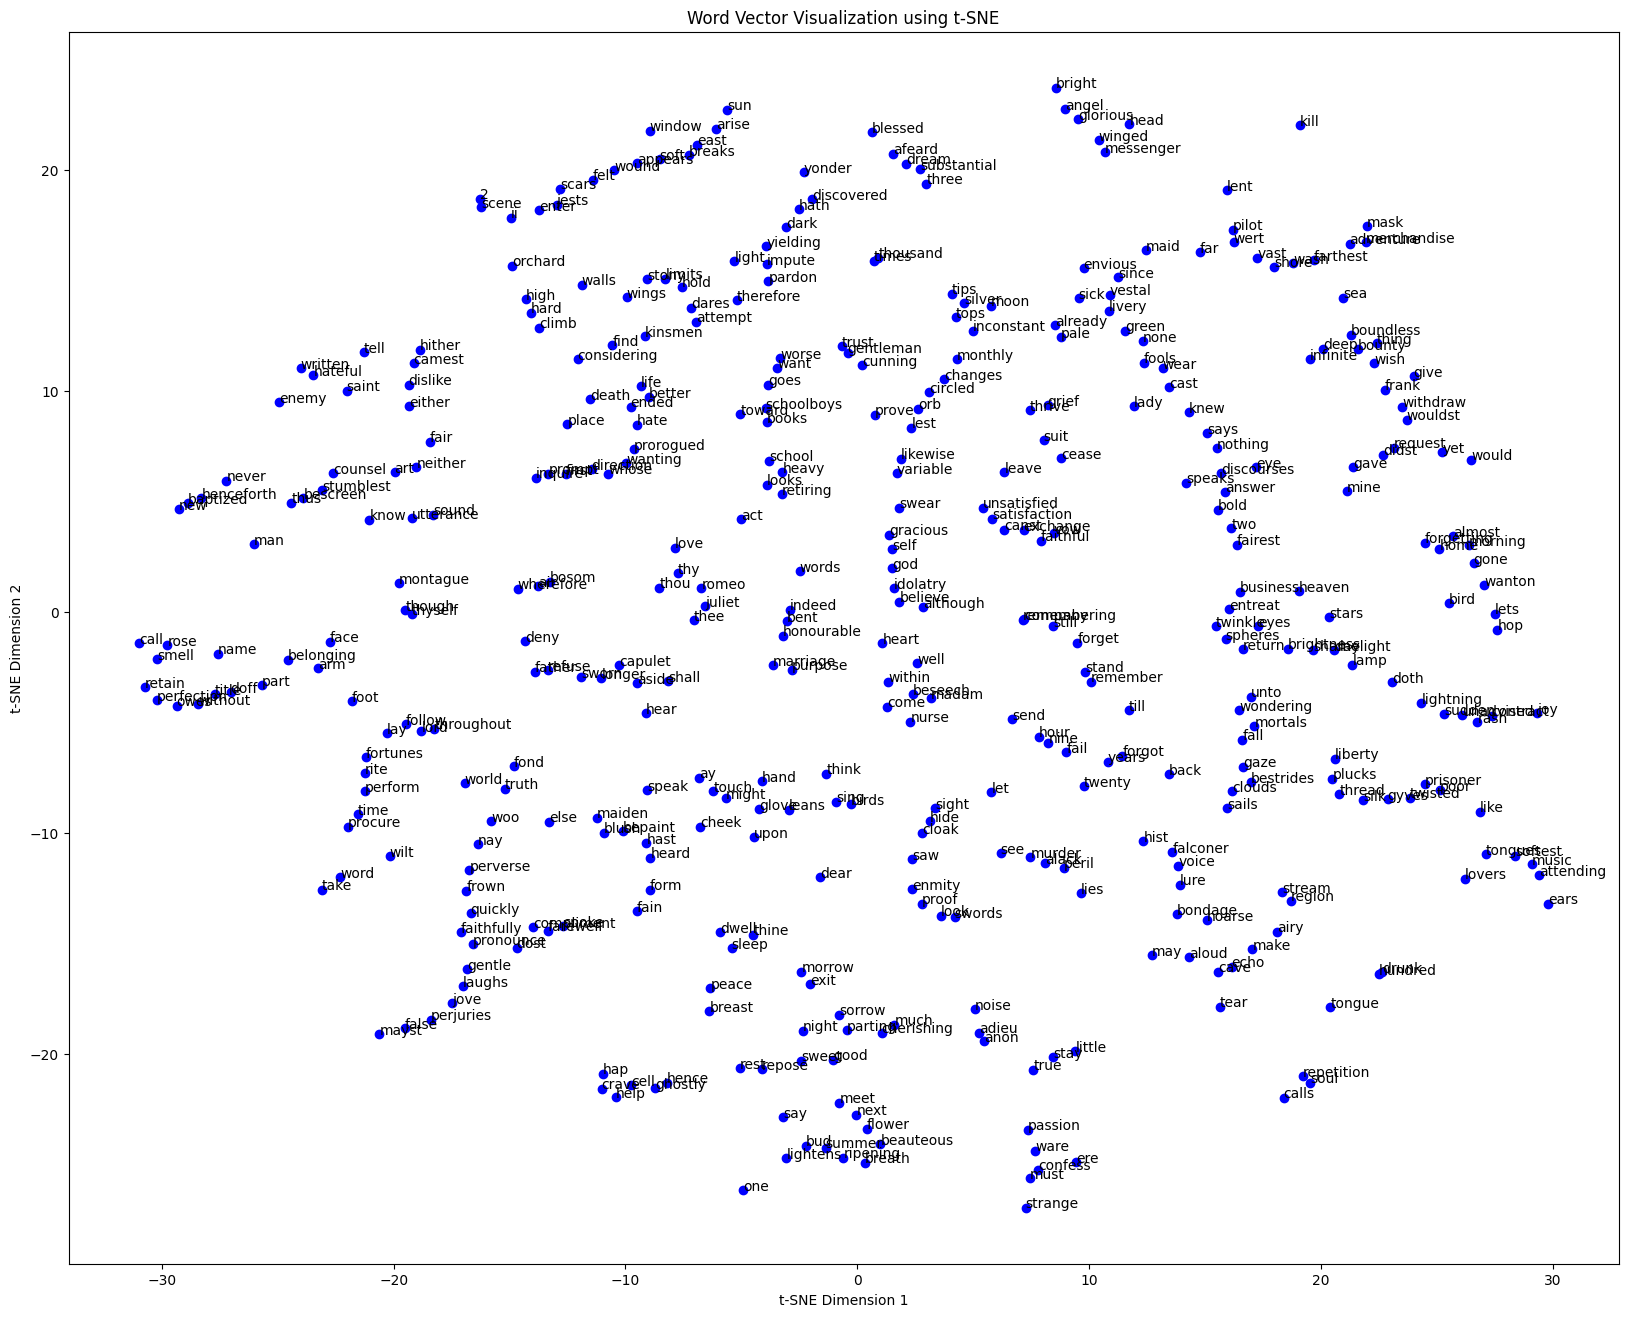

In [ ]:
tsne = TSNE(n_components=2, random_state=42)
word_vectors_2d = tsne.fit_transform(model.wv.vectors)

plt.figure(figsize=(20, 16))
plt.scatter(word_vectors_2d[:, 0], word_vectors_2d[:, 1], c='blue')

for word in model.wv.index_to_key:
    idx = model.wv.key_to_index[word]
    if idx is not None:
        plt.annotate(str(word), (word_vectors_2d[idx, 0], word_vectors_2d[idx, 1]))

plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.title('Word Vector Visualization using t-SNE')
plt.show()

marriage: 0.4830573797225952
thy: 0.4671194851398468
purpose: 0.45126989483833313
dares: 0.44287651777267456
honourable: 0.4413871169090271
attempt: 0.42267876863479614
limits: 0.42062807083129883
hold: 0.4188295304775238
wilt: 0.41240057349205017
bent: 0.4065127670764923


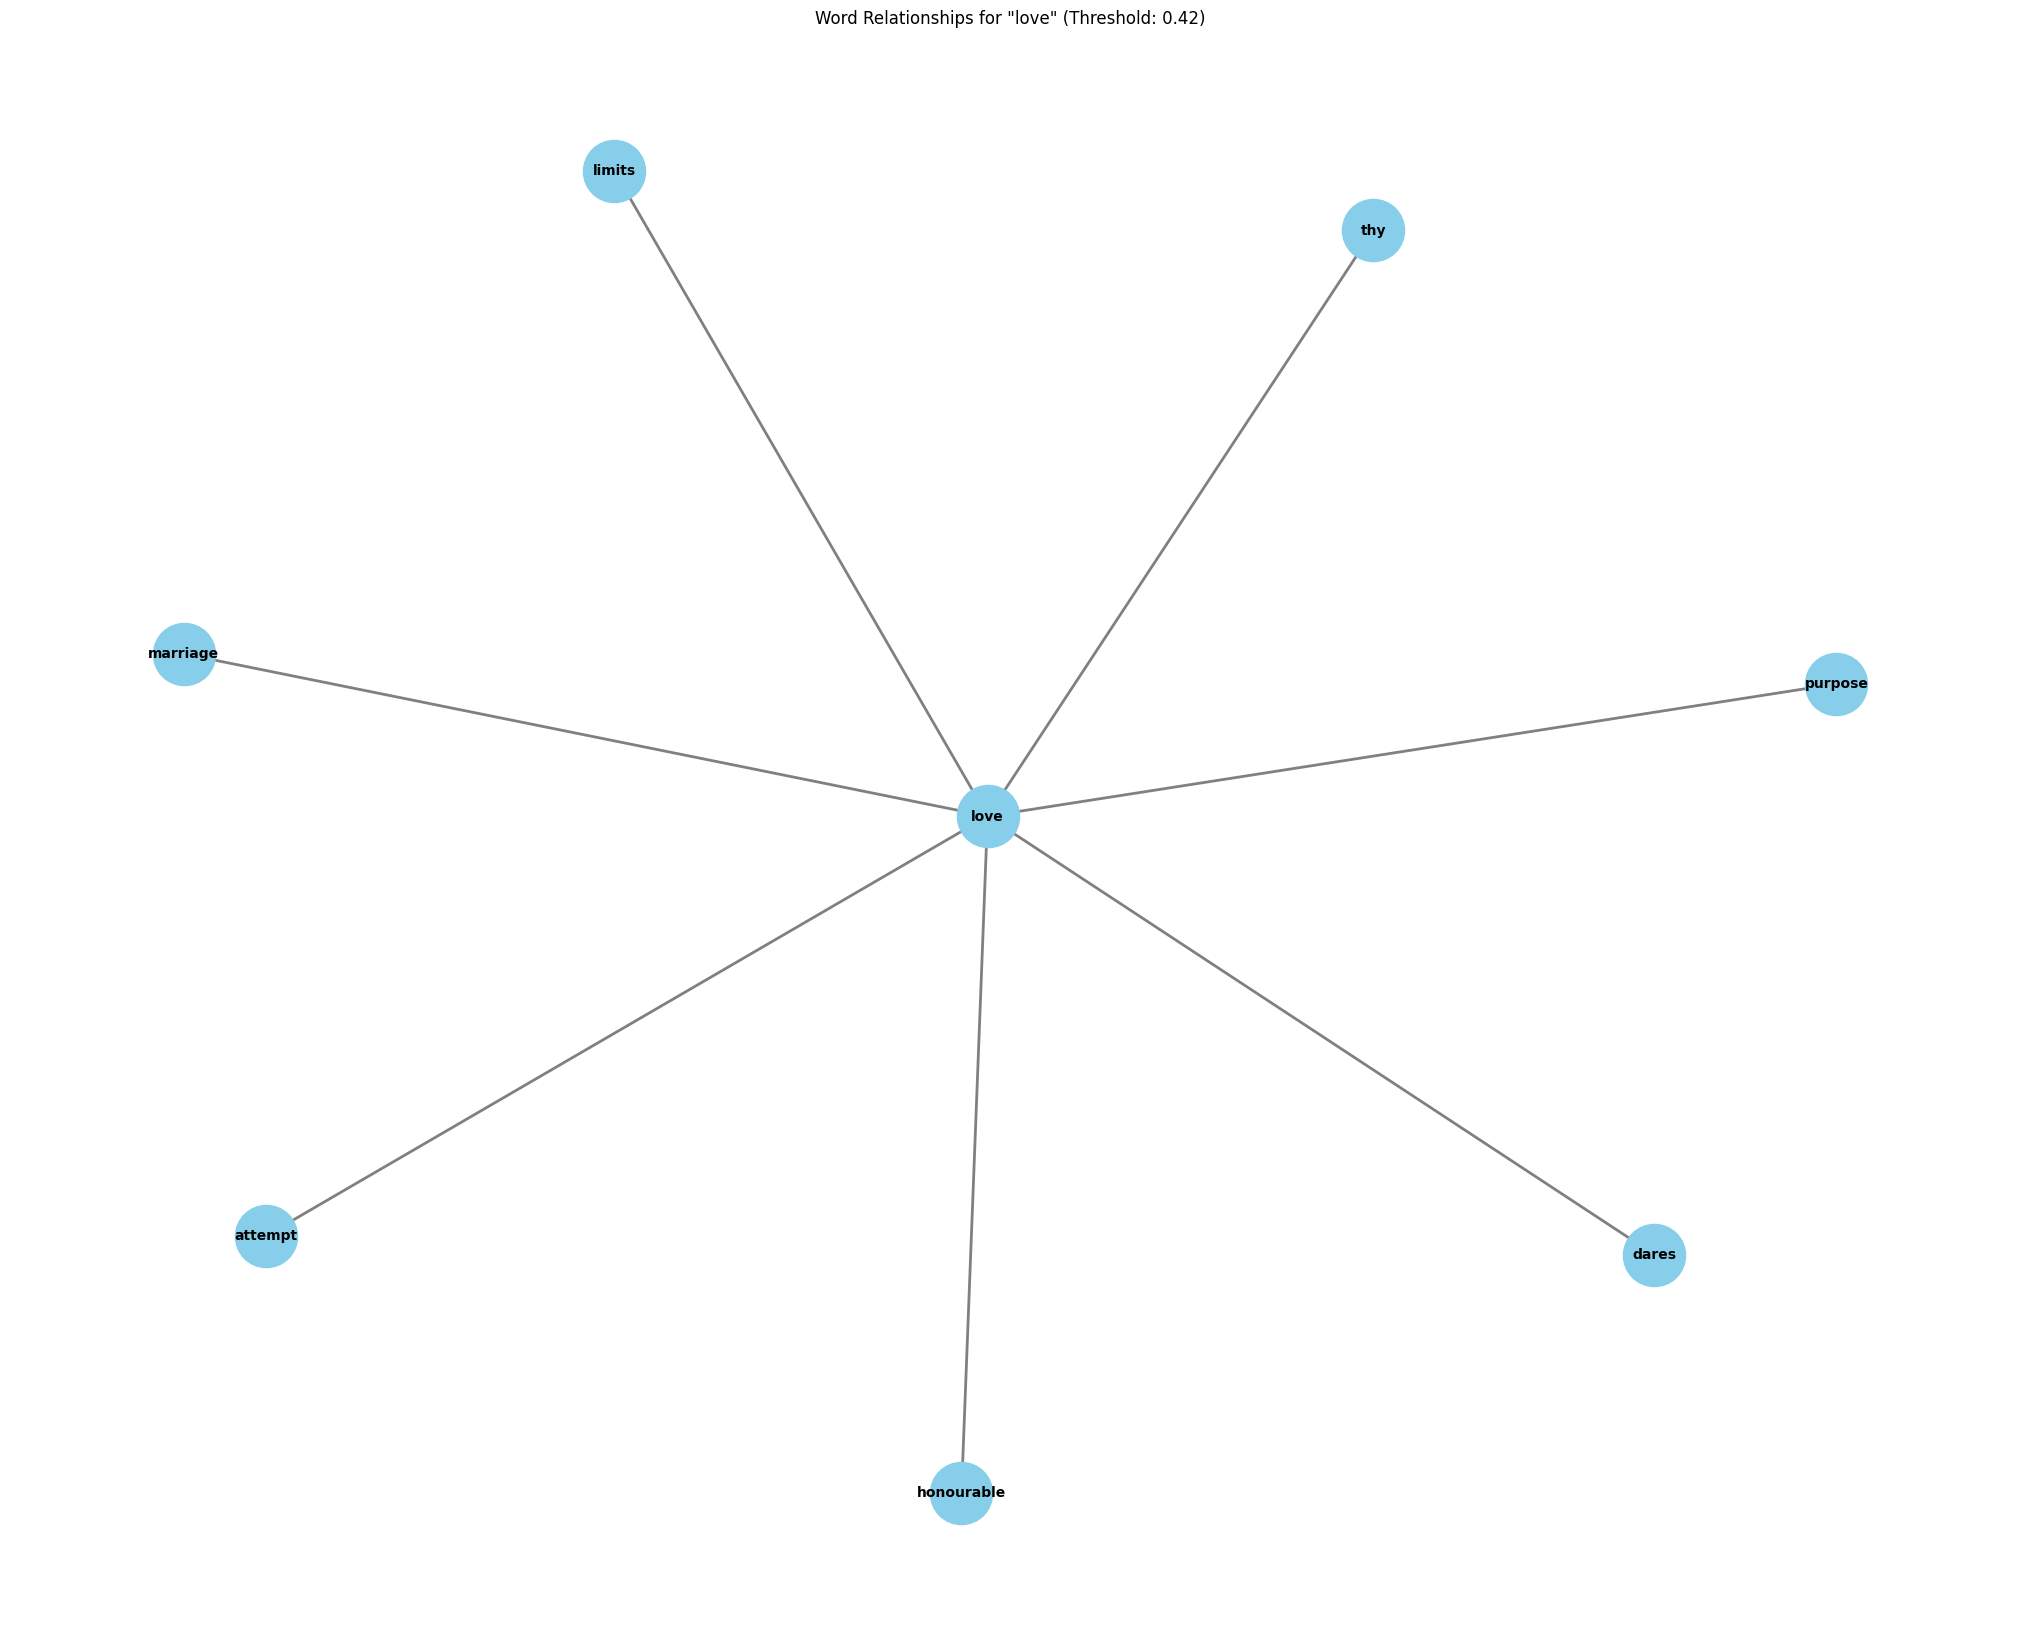

In [5]:
# Function to create a graph of similar words
def create_similarity_graph(word, word_vectors, threshold=0.5):
    G = nx.Graph()
    G.add_node(word)
    similar_words = word_vectors.most_similar(word)
    for similar_word, similarity in similar_words:
        print(f'{similar_word}: {similarity}')
        if similarity > threshold:
            G.add_node(similar_word)
            G.add_edge(word, similar_word, weight=similarity)
    return G

WORD = 'love'
THRESHOLD = 0.42
G = create_similarity_graph(WORD, model.wv, THRESHOLD)

plt.figure(figsize=(20, 16))
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_size=2000, node_color='skyblue', font_size=10, font_weight='bold', edge_color='gray', width=2)
plt.title(f'Word Relationships for "{WORD}" (Threshold: {THRESHOLD})')
plt.show()

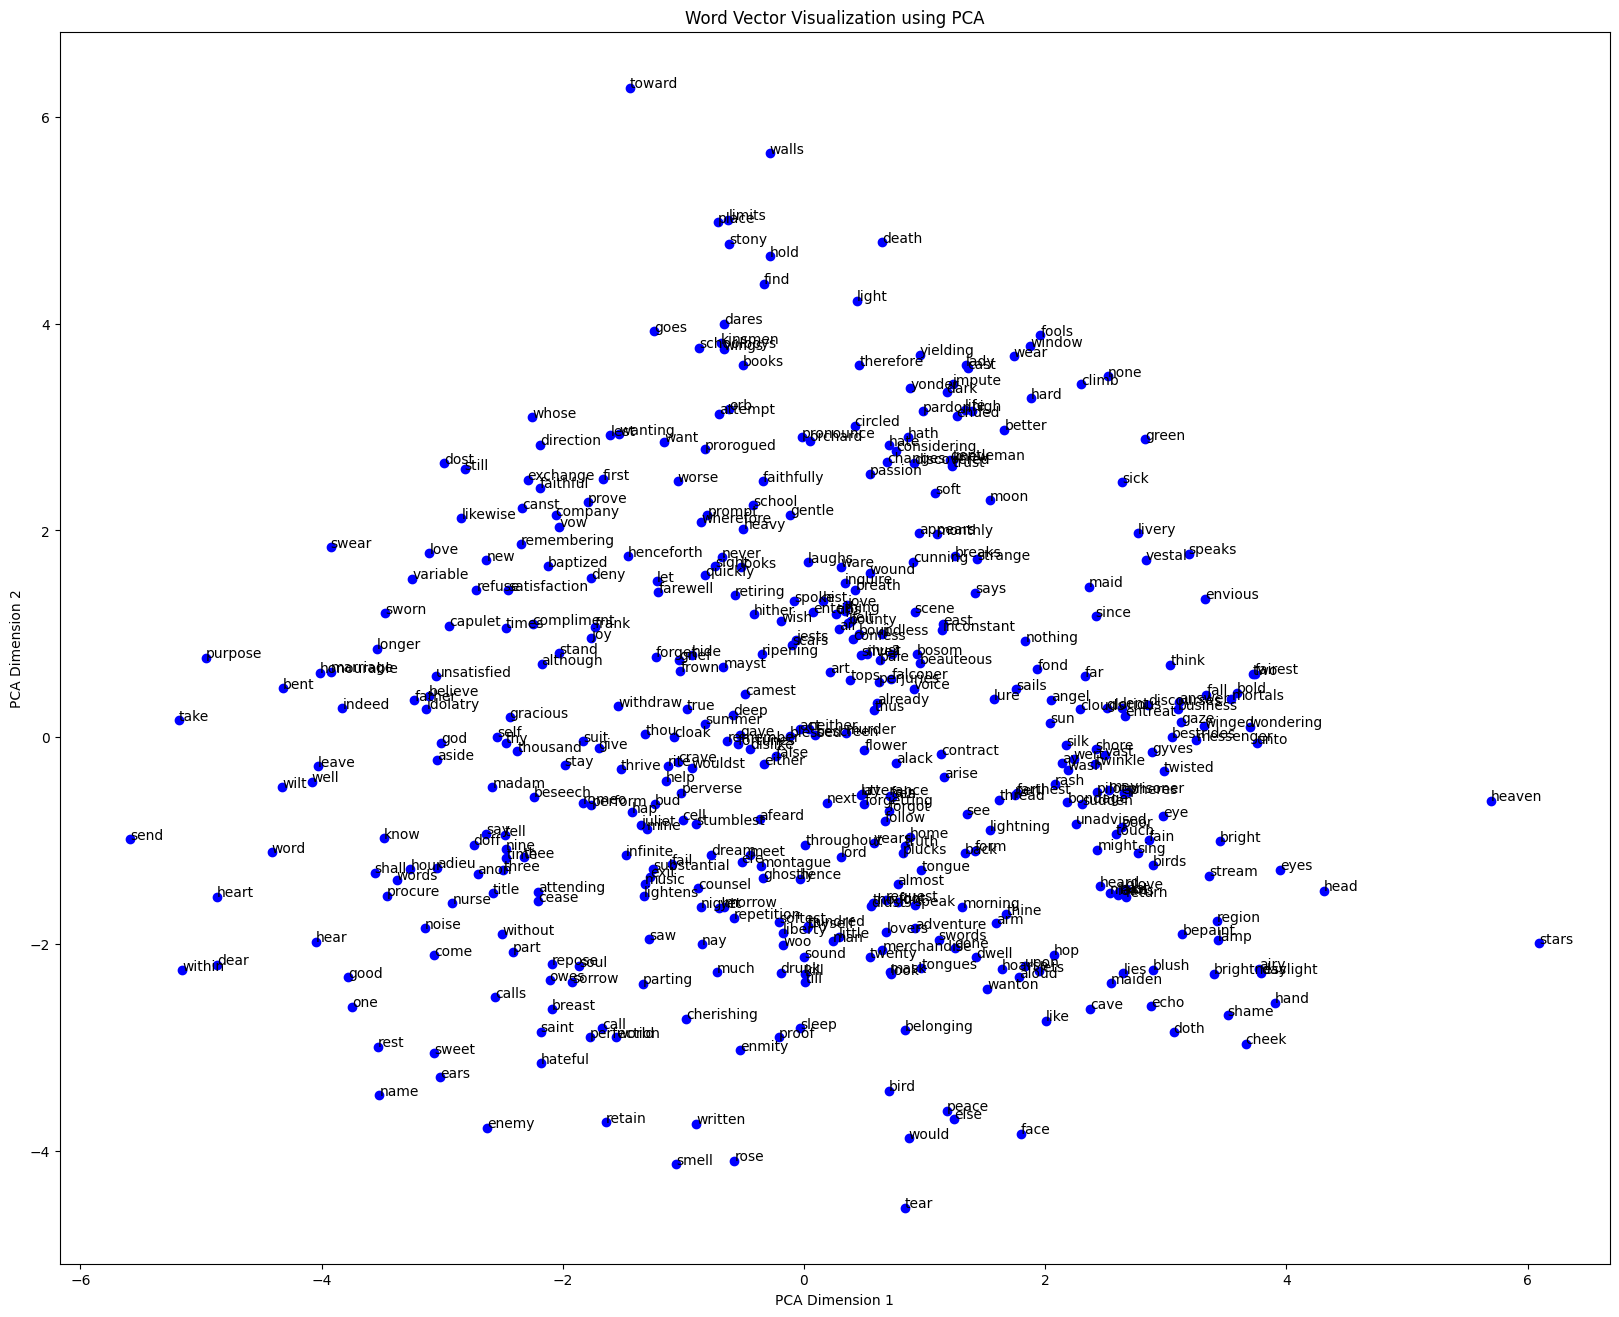

In [20]:
# Perform PCA for dimensionality reduction
pca = PCA(n_components=2)
word_vecs_2d = pca.fit_transform(model.wv.vectors)

# Show it
plt.figure(figsize=(20, 16))
plt.scatter(word_vecs_2d[:, 0], word_vecs_2d[:, 1], c='blue')
for word in model.wv.index_to_key:
    idx = model.wv.key_to_index[word]
    if idx is not None:
        plt.annotate(str(word), (word_vecs_2d[idx, 0], word_vecs_2d[idx, 1]))

plt.xlabel('PCA Dimension 1')
plt.ylabel('PCA Dimension 2')
plt.title('Word Vector Visualization using PCA')
plt.show()

The text source is Act2, Scene 2 of William Shakespeare's play "Romeo and Juliet". The passage consists of 874 tokens. Each token was feed to a Word2Vec model for training and converted into a numerical vector. Because Word2Vec is an unsupervised learning model, there is no simple way to calculate its accuracy. Thus, I tested it with a handful of word pairs to see if the similarity scores made sense. Similar word pairs such as "sun"/"moon" and "thou"/"thee" typically had higher similarity scores than dissimilar pairs such as "wherfore"/"lightning", seemingly indicating that the model is fairly accurate. The visualization created by the t-distributed Stochastic Neighbor Embedding also seems to have worked well; groups of words such as "face, "arm", and "foot", "satisfaction" and "unsatisfied", and "romeo" and "juliet". The visualization by Principal Components Analysis also seems to have worked well, closely palceing such words as "heaven"/"stars" and "eyes/"head". It's interesting though that there are differences between the two dimension reduction methods; "face"/"arm" are much further away from each other in the PCA graph, while "peace"/"else" are much further away from each other on the t-SNE graph.